# Поиск оптимальной стратегии методом SARSA

Реализуем метод **SARSA** для поиска оптимальной стратегии с помощью **обобщённой итерации по 𝜀-мягким стратегиям** с GLIE, то есть с постепенным убыванием 𝜀. 

Написанный ранее абстрактный класс с "табличным" агентом для обучения табличной Q-функции, содержал следующие базовые методы:

    reset()       - сброс значений Q-функции;
    update_Q()    - обновления значений Q(s,a) в сторону цели обновления goal;
    get_action()  - выбор действий по eps-жадной стратегии относительно текущей Q-функции;
    best_action() - выбор жадного действия относительно текущей Q-функции;
    play()        - запуск симуляции взаимодействия обученного агента со средой.

А также функции для сохранения и подгрузки значений Q-функции.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import os
from tqdm import tqdm
import pickle

from abc import ABC, abstractmethod
from collections import defaultdict


class QTableAgent(ABC):
    def __init__(self, env, eps = 0.1, alpha = 0.1):
        self.nA = env.action_space.n # число действий
        self.N = defaultdict(lambda: np.zeros(self.nA))
        # заполняемая таблица значений Q-функции, хранящая ценности пар состояние-действие
        self.Q = defaultdict(lambda: np.zeros(self.nA))
    
        self.eps = eps   
        self.alpha = alpha

    # выбор eps-жадного действия        
    def reset(self):
        self.N = defaultdict(lambda: np.zeros(self.nA))
        self.Q = defaultdict(lambda: np.zeros(self.nA))

    # выбор eps-жадного действия        
    def get_action(self, state):
        if np.random.rand() < self.eps:
            return np.random.choice(self.nA)
        return self.best_action(state)
    
    # выбор жадного действия        
    def best_action(self, state):
        return np.argmax(self.Q[state])

    def get_Q(self, state, act):
        return self.Q[state][act]

    def update_Q(self, state, act, goal):
        # обновление оценки по методу выборочного среднего или с постоянным шагом обновления
        if self.alpha is None:
            self.N[state][act] += 1
            self.Q[state][act] += (goal - self.Q[state][act])/self.N[state][act]
        else:
            self.Q[state][act] += self.alpha*(goal - self.Q[state][act])

    @abstractmethod
    def learn(self):
        """Метод обучения"""
        pass

    def play(self, env, n_episodes):
        """Оценка качества обученного агента. """
        for _ in tqdm(range(n_episodes)):
            state, _ = env.reset()
            while True:
                # выбираем лучшие действия
                action = self.best_action(state)
                state, reward, terminated, truncated, _ = env.step(action)
                if terminated or truncated:
                    break

    def save_Q(self, name):
        os.makedirs('savedModels', exist_ok=True)
        with open('savedModels/TableAgent_'+name+".pkl",'wb') as f:
            pickle.dump(dict(self.Q), f)
        return 'savedModels/TableAgent_'+name+".pkl"
        
    def load_Q(self, name):
        self.reset()
        with open(name, 'rb') as f:
            loaded_data = pickle.load(f)
            self.Q = defaultdict(lambda: np.zeros(self.nA), loaded_data) 

Сформируем класс агента, обучающегося по методу SARSA и реализуем метод:

    learn()    - алгоритм обучения по методу SARSA

Значения гиперпараметров будем хранить в структуре `dataclass`.

In [2]:
from dataclasses import dataclass

@dataclass
class ConfigTD:
    gamma: float = 0.99
    eps_start: float = 1.0
    eps_decay: float = 0.999
    eps_min: float = 0.01
    alpha_start: float = 0.1
    alpha_decay: float = 0.99
    alpha_min: float = 0.05

class SARSA_Agent(QTableAgent): 
    def __init__(self, env, config = None):
        super().__init__(env)
        if config is None:
            self.config = ConfigTD()
        else:
            self.config = config
            
        self.env = env
        self.alpha = self.config.alpha_start
        self.eps = self.config.eps_start
        self.gamma = self.config.gamma
        

    def learn(self, n_episodes = 1000, restart = True):
        if restart == True:
            self.alpha = self.config.alpha_start
            self.eps = self.config.eps_start 
            self.reset()
            
        # ===== работа алгоритма обучения  =====
        for i in tqdm(range(n_episodes)):
            state, _ = self.env.reset()
            action = self.get_action(state)
            # запускаем эпизод взаимодействия со средой
            
            while True:
                next_state, reward, terminated, truncated, _ = self.env.step(action)
                next_action = self.get_action(next_state)
                upd_goal = reward + (1-terminated) * self.gamma * self.get_Q(next_state,next_action)
                self.update_Q(state, action, upd_goal)                
                    
                if terminated or truncated:
                    break
                state, action = next_state, next_action  
                
            # уменьшение доли шагов исследования
            self.eps = max(self.eps * self.config.eps_decay, self.config.eps_min)         
            if self.alpha is not None:
                self.alpha = max(self.alpha * self.config.alpha_decay, self.config.alpha_min)   

### Пример 1

Рассмотрим задачу о сеточном мире `CliffWalking-v1` из библиотеки `gymnaisum`. Она полезна для наглядного сравнения некоторых особенностей работы трёх TD-методов: SARSA, Q-learning, Expected SARSA.

Сеточный мир представляет собой матрицу из клеток размера 4 на 12 клеток, индексация клеток такая же, что и у матрицы размера 4 на 12 в `Python`.
	
1. Клетка $(3,0)$ - это стартовое состояние.
2. Клетка $(3,11)$ - это заключительное состояние.
3. Клетки $(3,1)$,...,$(3,10)$ представляют собой утёс.

4 действия: влево, вниз, вправо, вверх, перемещают агента по полю с клетками, выход за пределы поля означает, что агент остаётся на месте. 

Вознаграждения: 

    -1 за каждый временной шаг, 
    -100 на попадание на клетку с утёсом и возвращение в стартовую клетку. 
    
В заключительном состоянии эпизод завершается.

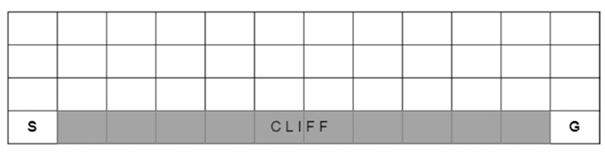

Рассмотрим решение этой задачи методом SARSA.

In [3]:
import gymnasium as gym

# Создание среды
env = gym.make('CliffWalking-v1')
n_episodes = 5000
env = gym.wrappers.RecordEpisodeStatistics(env, n_episodes)

config = ConfigTD(gamma = 0.99,
                eps_start = 1.0, 
                eps_decay = 0.99, 
                eps_min = 0.001,                
                alpha_start = 0.25, 
                alpha_decay = 1.0, 
                alpha_min = 0.01
               )

# создание табличного агента
agent = SARSA_Agent(env, config)


# обучение агента и получение доходов по эпизодам
agent.learn(n_episodes = n_episodes)

100%|██████████| 5000/5000 [00:02<00:00, 2046.46it/s]


Выведем график доходов за эпизоды, полученных в взаимодействия агента со средой.

In [4]:
import matplotlib.pyplot as plt
# для того, чтобы избежать ошибок при построении графиков
#import os
#os.environ["KMP_DUPLICATE_LIB_OK"]="TRUE"

# в названии графика среднее вознаграждение за 20 последних эпизодов
def plot_rewards(env_name, returns, label):
    fig = plt.figure(figsize=(16, 4))
    plt.title("Среда: "+env_name+", Средний доход за последние 20 эпизодов = "+str(np.mean(returns[-20:])))
    plt.plot(returns, label=label)
    plt.grid()
    plt.legend()
    plt.ylim(-100, 0)
    plt.show()

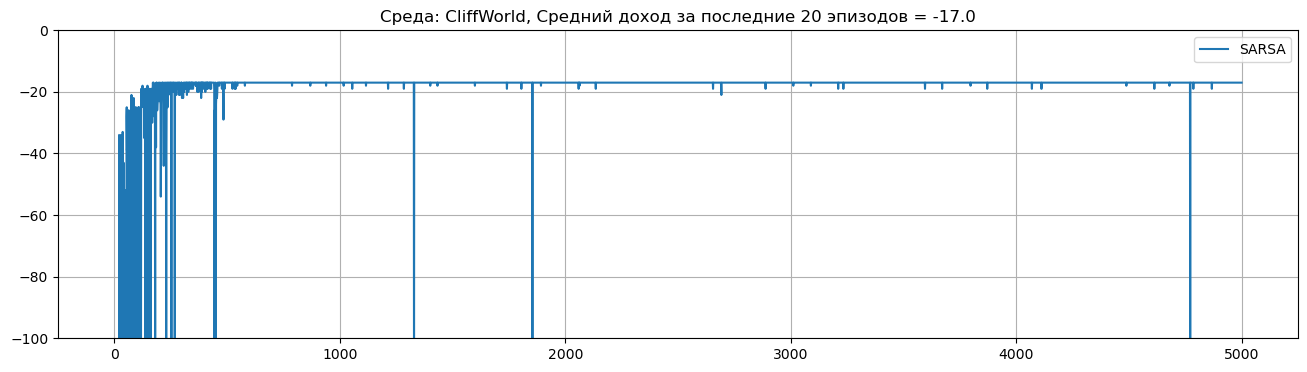

In [5]:
# график доходов
returns = np.array(env.return_queue)
plot_rewards("CliffWorld", returns, 'SARSA')

График доходов по эпизодам показывает, что уже к 500 эпизоду агент достиг фиксированной стратегии. Общий доход близок к оптимальному, хотя и не оптимален. Рассмотрим стратегию, которой обучился агент.

In [6]:
# создание экземпляра среды
env = gym.make('CliffWalking-v1', render_mode='human')
env = gym.wrappers.RecordEpisodeStatistics(env)

agent.play(env, 1)

print("Число шагов:", env.length_queue[-1])
# завершить взаимодействие со средой
env.close()

  0%|          | 0/1 [00:00<?, ?it/s]D:\anaconda3\Lib\site-packages\pygame\pkgdata.py:25: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import resource_stream, resource_exists
100%|██████████| 1/1 [00:06<00:00,  6.68s/it]

Число шагов: 17


In [7]:
import time
from IPython.display import clear_output

env = gym.make("CliffWalking-v1", render_mode='ansi')
env = gym.wrappers.RecordEpisodeStatistics(env)

state, _ = env.reset()
print(env.render())

while True:
    state, reward, terminated, truncated, _ = env.step(agent.get_action(state)) 
    
    time.sleep(.2)
    clear_output(wait=True)
    print(env.render())

    if terminated or truncated:
        break

print("Число шагов:", env.length_queue[-1])
env.close()

o  o  o  o  o  o  o  o  o  o  o  o
o  o  o  o  o  o  o  o  o  o  o  o
o  o  o  o  o  o  o  o  o  o  o  o
o  C  C  C  C  C  C  C  C  C  C  x


Число шагов: 17


Можно вывести жадные действия агента относительно обученной Q-функции, используя метод `agent.best_action()`.

In [8]:
opt_actions = np.zeros(48)
for s in range(48):
    opt_actions[s] = agent.best_action(s)

opt_actions.reshape(4,12)    

array([[1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 2.],
       [0., 0., 0., 0., 0., 0., 1., 0., 0., 0., 1., 2.],
       [0., 0., 0., 1., 0., 0., 0., 0., 0., 0., 1., 2.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.]])

Агент обучился стратегии, которая обходит утёс как можно дальше. Ясно, что это не кратчайший путь для достижения цели и эта стратегия не оптимальна. В случае детеминированной стратегии, лучший вариант будет на 4 шага короче и путь будет проходить вдоль утёса.

Почему агент обучился именно такой "безопасной" стратегии? Это объясняется тем, что SARSA в ходе обучения совершает итерации по $\varepsilon$-жадным стратегиям и всегда есть малый шанс свалиться с утёса, если проходить вдоль него. 

Этот пример подсвечивает одну из проблем методов обучения с единой стратегией: **исследовательские действия агента могут мешать нахождению оптимальной стратегии**, поскольку случайные действия могут переместить агента в состояния с низкой ценностью.

Этого можно будет избежать при обучении по методу Q-learning, который является методом с разделённой стратегией. В рамках этого метода агент генерирует траектории по исследовательской поведенческой стратегии, а обучается целевой оптимальной детерминированной стратегии.

### Пример 2 

Применим метод SARSA для обучения табличного агента для решения задачи о такси `Taxi-v4`.

In [10]:
import gymnasium as gym

# Создание среды
env = gym.make('Taxi-v4')
n_episodes = 40000
env = gym.wrappers.RecordEpisodeStatistics(env, n_episodes)

config = ConfigTD(gamma = 0.9999,
                eps_start = 1.0, 
                eps_decay = 0.9999, 
                eps_min = 0.001,                
                alpha_start = 0.05, 
                alpha_decay = 1.0, 
                alpha_min = 0.01
               )

# создание табличного агента
agent = SARSA_Agent(env, config)


# обучение агента и получение доходов по эпизодам
agent.learn(n_episodes = n_episodes)

100%|██████████| 40000/40000 [00:44<00:00, 902.18it/s] 


Выведем график доходов за эпизоды, полученных в взаимодействия агента со средой.

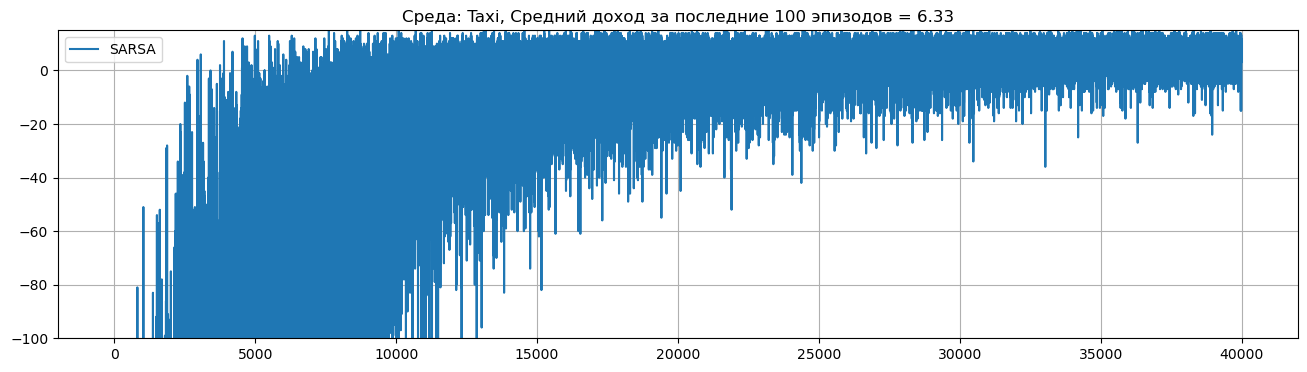

In [11]:
def plot_rewards(env_name, returns, label):
    fig = plt.figure(figsize=(16, 4))
    plt.title("Среда: "+env_name+", Средний доход за последние 100 эпизодов = "+str(np.mean(returns[-100:])))
    plt.plot(returns, label=label)
    plt.grid()
    plt.legend()
    plt.ylim(-100, 15)
    plt.show()

# график доходов
returns = np.array(env.return_queue)
plot_rewards("Taxi", returns, 'SARSA')

Сначала обучение идёт довольно медленно, поскольку агент действует по eps-стратегии с высоким eps. Но в ходе взаимодействия, с накоплением опыта, получением достаточно хороших оценок и снижением eps, агент действует по всё более хорошей стратегии, и число шагов на эпизод снижается.

Запустим симуляцию для обученного агента на 10 000 эпизодах и найдём среднее вознаграждение.

In [11]:
agent.save_Q("Taxi_SARSA")

'savedModels/TableAgent_Taxi_SARSA.pkl'

In [12]:
agent = SARSA_Agent(env, config)
agent.load_Q('savedModels/TableAgent_Taxi_SARSA.pkl')

In [13]:
n_episodes = 10000
env = gym.make("Taxi-v4")
env = gym.wrappers.RecordEpisodeStatistics(env, n_episodes)

agent.play(env, n_episodes)

100%|██████████| 10000/10000 [00:02<00:00, 3769.65it/s]


Можно вывести гистограмму полученных вознаграждений.

Средний доход за эпизод равен: 7.9067
Минимальный доход за эпизод равен: 3.0
Максимальный доход за эпизод равен: 15.0


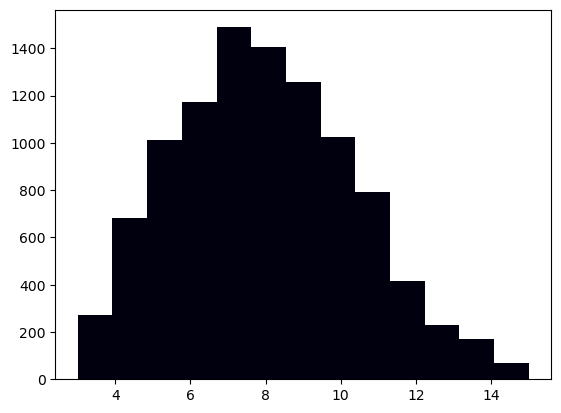

In [14]:
print('Средний доход за эпизод равен:', np.mean(env.return_queue))
print('Минимальный доход за эпизод равен:', np.min(env.return_queue))
print('Максимальный доход за эпизод равен:', np.max(env.return_queue))

import matplotlib.pyplot as plt
plt.hist(env.return_queue, bins=13, color='#00000f')
plt.show()

Из гистограммы ясно, что минимальное вознаграждение равно 3. Действительно, такое вознаграждение может быть при самом худшем варианте начального расположения. Например, такси в точке Y, пассажир в точке G, точка назначения в точке Y. Оптимальное движение займёт 17 временных шагов с посадкой пассажира и общий доход будет равен +3.

Косвенно это указывает на то, что найденная стратегия оптимальна.

In [15]:
import time
from IPython.display import clear_output

env = gym.make("Taxi-v4", render_mode='ansi')
state, _ = env.reset()
print(env.render())

while True:
    state, reward, terminated, truncated, _ = env.step(agent.best_action(state)) # выбрать действие случайно
    
    time.sleep(.1)
    clear_output(wait=True)      
    print(env.render())
    if terminated or truncated:
        break

env.close()

+---------+
|R: | : :G|
| : | : : |
| : : : : |
| | : | : |
|Y| : |B: |
+---------+
  (Dropoff)

